# 07 — Model Comparison

**Milestone 3 · Task 8.** Evaluate all models on Accuracy, Precision,
Recall, F1-score and ROC-AUC. Produce a comparison table and visualisation
identifying which perform best and where they differ.

Reads the three per-model CSVs written by `06a`, `06b` and `06c`, and refits
the primary configuration to draw ROC curves.

**If a model is missing from the table below, that person's notebook has not
been run yet.** The comparison still works with two of three.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from src.features import build_model_matrix
from src.modeling import make_models, align_columns
from src.evaluation import METRICS, majority_class_baseline, roc_points

mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
FIG = Path("../reports/figures")
EXTRA = ["log_city_project_count", "log_goal_vs_subcat_median"]

# Task 7 is split across three notebooks, one per model, each writing its own
# CSV. Concatenate them here. (Falls back to the combined file if a team used
# a single notebook instead.)
parts = []
for slug in ["logistic", "random_forest", "knn"]:
    f = Path(f"../reports/m3_task7_{slug}.csv")
    if f.exists():
        parts.append(pd.read_csv(f))
    else:
        print(f"  missing: {f.name} -- that model's notebook has not been run")

if parts:
    res = pd.concat(parts, ignore_index=True)
else:
    res = pd.read_csv("../reports/m3_task7_model_results.csv")
    print("  using combined fallback file")
train = pd.read_parquet("../data/m3_random_train.parquet")
test = pd.read_parquet("../data/m3_random_test.parquet")
floor = majority_class_baseline(train["success"], test["success"])
FLOOR_ACC = float(floor["accuracy"].iloc[0])
print(f"{len(res)} model runs loaded. Floor: {FLOOR_ACC:.1%} accuracy")

12 model runs loaded. Floor: 54.7% accuracy


## 8.1 The comparison table

Primary configuration first: launch-time features, random split.

In [2]:
primary = res[(res.feature_set == "launch_only") & (res.split == "random")]
table = pd.concat([floor, primary], ignore_index=True)
table = table.sort_values("f1", ascending=False).reset_index(drop=True)
table[["model"] + METRICS].round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Random Forest,0.7153,0.7041,0.8277,0.7609,0.7798
1,Logistic Regression,0.7160,0.7175,0.7936,0.7536,0.7770
2,KNN,0.6528,0.6453,0.8119,0.7191,0.7026
3,Majority class,0.5473,0.5473,1.0000,0.7074,0.5000


## 8.2 Metrics side by side

Reading all five together matters. A model can win on accuracy and lose on
recall, and which you prefer depends on whether a false encouragement or a
false discouragement is the worse outcome.

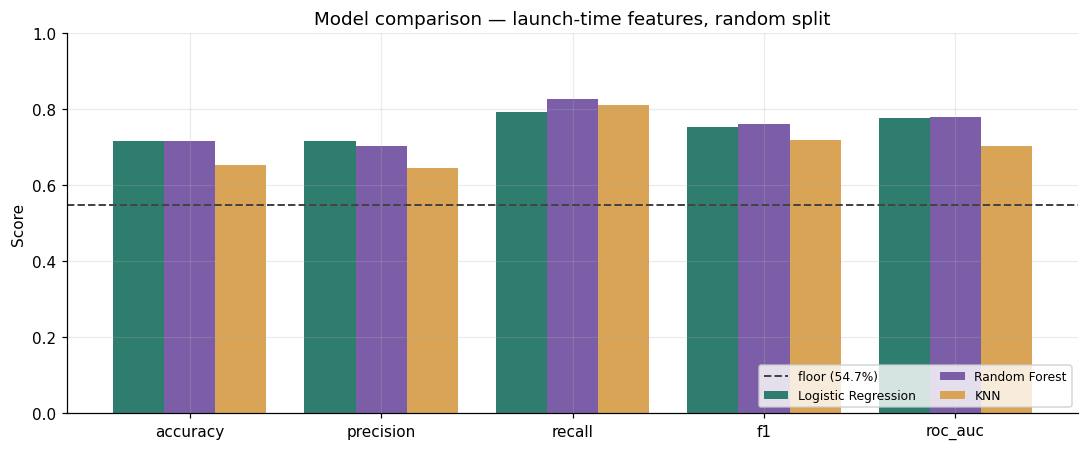

In [3]:
models = primary.model.tolist()
x = np.arange(len(METRICS))
w = 0.8 / len(models)
colors = [TEAL, PLUM, SAND, CORAL][:len(models)]

fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (m, c) in enumerate(zip(models, colors)):
    row = primary[primary.model == m].iloc[0]
    ax.bar(x + i * w, [row[k] for k in METRICS], w, label=m, color=c)
ax.axhline(FLOOR_ACC, color="#444", ls="--", lw=1.3, label=f"floor ({FLOOR_ACC:.1%})")
ax.set_xticks(x + w * (len(models) - 1) / 2)
ax.set_xticklabels(METRICS)
ax.set_ylim(0, 1.0); ax.set_ylabel("Score")
ax.set_title("Model comparison — launch-time features, random split")
ax.legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "m3_model_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

## 8.3 ROC curves

ROC-AUC is the most useful single number here because it does not depend on
the 0.5 decision threshold. Two models can share an accuracy score while
ranking campaigns very differently.

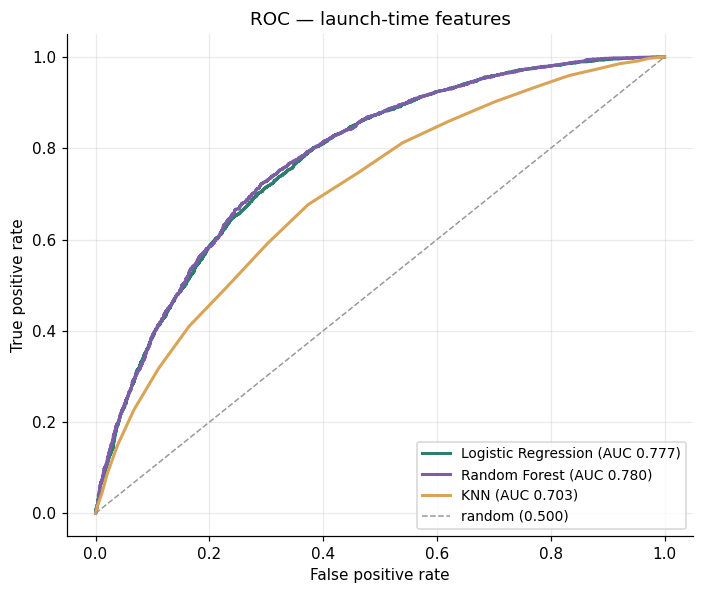

In [4]:
X_train, y_train = build_model_matrix(train, "launch_only", extra_numeric=EXTRA)
X_test, y_test = build_model_matrix(test, "launch_only", extra_numeric=EXTRA)
X_test = align_columns(X_train, X_test)

fitted = {}
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for (label, model), c in zip(make_models().items(), [TEAL, PLUM, SAND]):
    model.fit(X_train, y_train)
    fitted[label] = model
    fpr, tpr, auc = roc_points(model, X_test, y_test)
    ax.plot(fpr, tpr, color=c, lw=2, label=f"{label} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1, label="random (0.500)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC — launch-time features")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "m3_roc_curves.png", dpi=130, bbox_inches="tight")
plt.show()

## 8.4 Feature set and split effects

Two questions at once: what does excluding `updates` cost, and does the
chronological split change the ranking?

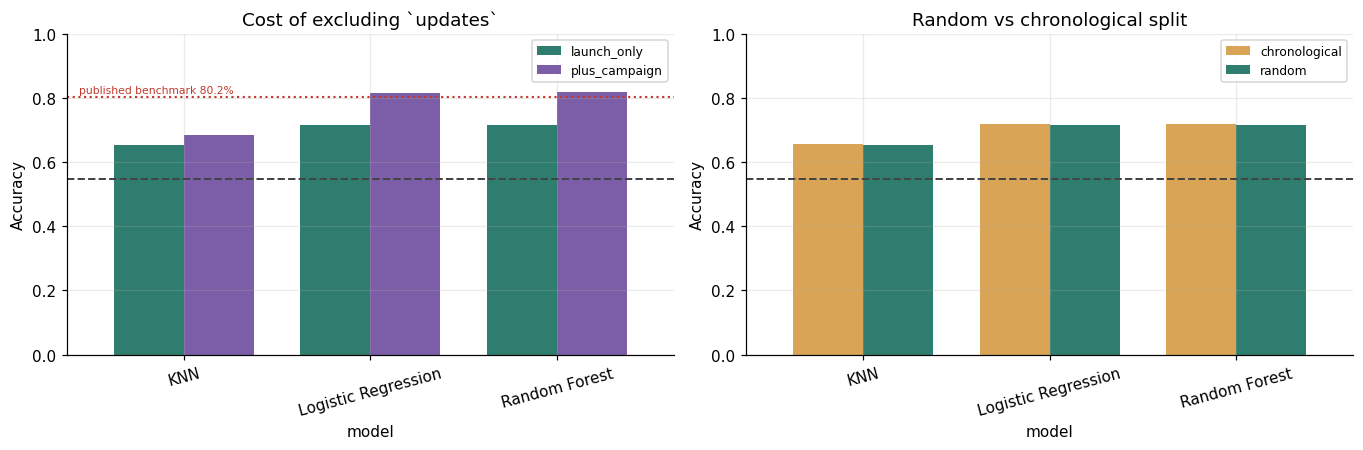

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

pivot_fs = res[res.split == "random"].pivot(
    index="model", columns="feature_set", values="accuracy")
pivot_fs.plot.bar(ax=axes[0], color=[TEAL, PLUM], rot=15, width=0.75)
axes[0].axhline(FLOOR_ACC, color="#444", ls="--", lw=1.3)
axes[0].axhline(0.802, color=CORAL, ls=":", lw=1.4)
axes[0].set_title("Cost of excluding `updates`")
axes[0].set_ylabel("Accuracy"); axes[0].set_ylim(0, 1.0)
axes[0].legend(fontsize=8, title=None)
axes[0].text(0.02, 0.815, "published benchmark 80.2%", fontsize=7,
             color=CORAL, transform=axes[0].get_yaxis_transform())

pivot_sp = res[res.feature_set == "launch_only"].pivot(
    index="model", columns="split", values="accuracy")
pivot_sp.plot.bar(ax=axes[1], color=[SAND, TEAL], rot=15, width=0.75)
axes[1].axhline(FLOOR_ACC, color="#444", ls="--", lw=1.3)
axes[1].set_title("Random vs chronological split")
axes[1].set_ylabel("Accuracy"); axes[1].set_ylim(0, 1.0)
axes[1].legend(fontsize=8, title=None)

plt.tight_layout()
plt.savefig(FIG / "m3_featureset_and_split.png", dpi=130, bbox_inches="tight")
plt.show()

In [6]:
print("Accuracy by feature set (random split):")
print(pivot_fs.round(4).to_string())
print("\nAccuracy by split (launch-time features):")
print(pivot_sp.round(4).to_string())

Accuracy by feature set (random split):
feature_set          launch_only  plus_campaign
model                                          
KNN                       0.6528         0.6855
Logistic Regression       0.7160         0.8158
Random Forest             0.7153         0.8180

Accuracy by split (launch-time features):
split                chronological  random
model                                     
KNN                         0.6567  0.6528
Logistic Regression         0.7177  0.7160
Random Forest               0.7200  0.7153


## 8.5 Threshold sensitivity

Every metric above assumes a 0.5 cutoff. Moving it trades precision against
recall, and the right choice depends on which error is worse — a question
Milestone 4 has to answer rather than inherit.

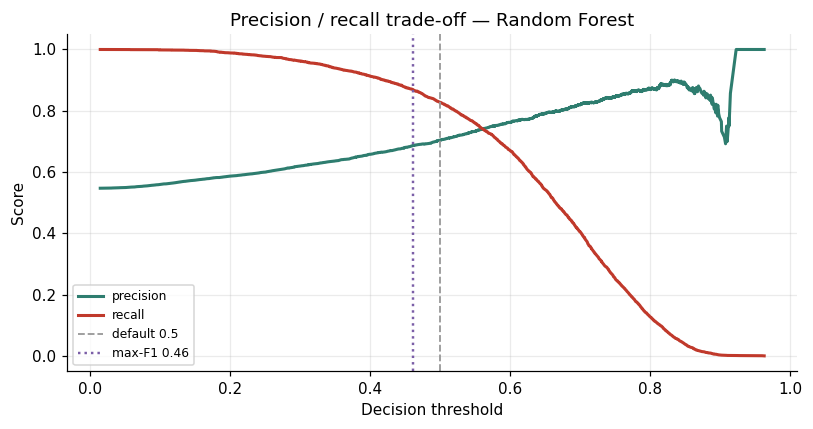

Default threshold 0.50 -> F1 0.761
Best threshold 0.46 -> F1 0.767


In [7]:
from sklearn.metrics import precision_recall_curve

leader_name = primary.sort_values("f1", ascending=False).model.iloc[0]
leader = fitted[leader_name]
proba = leader.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(thr, prec[:-1], color=TEAL, lw=2, label="precision")
ax.plot(thr, rec[:-1], color=CORAL, lw=2, label="recall")
f1_curve = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
best_thr = thr[int(np.argmax(f1_curve))]
ax.axvline(0.5, color="#999", ls="--", lw=1.2, label="default 0.5")
ax.axvline(best_thr, color=PLUM, ls=":", lw=1.6, label=f"max-F1 {best_thr:.2f}")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score")
ax.set_title(f"Precision / recall trade-off — {leader_name}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m3_threshold_tradeoff.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"Default threshold 0.50 -> F1 {f1_curve[np.argmin(np.abs(thr - 0.5))]:.3f}")
print(f"Best threshold {best_thr:.2f} -> F1 {f1_curve.max():.3f}")

## 8.6 Candidates to carry into tuning

In [8]:
ranked = primary.sort_values("f1", ascending=False)[["model"] + METRICS].round(4)
print(ranked.to_string(index=False))
print(f"\nCarrying forward the top two by F1: "
      f"{', '.join(ranked.model.head(2))}")

table.to_csv("../reports/m3_task8_comparison.csv", index=False)
print("\nWrote ../reports/m3_task8_comparison.csv")

              model  accuracy  precision  recall     f1  roc_auc
      Random Forest    0.7153     0.7041  0.8277 0.7609   0.7798
Logistic Regression    0.7160     0.7175  0.7936 0.7536   0.7770
                KNN    0.6528     0.6453  0.8119 0.7191   0.7026

Carrying forward the top two by F1: Random Forest, Logistic Regression

Wrote ../reports/m3_task8_comparison.csv


## Task 8 — Summary

- All five metrics reported for every model, always against the 54.7% /
  0.71 F1 floor.
- ROC-AUC is the fairest single comparison because it is threshold-free.
- The `updates` gap and the chronological-split gap are both quantified
  rather than assumed.
- The default 0.5 threshold is a choice, not a law — the precision/recall
  curve shows what moving it buys.

**Next:** `08_tuning.ipynb` performs feature selection, hyperparameter
tuning and class balancing on the leading candidates.